# Session 7 — Convolutional Neural Networks

**Question:** the network now sees the pixels. Does that beat the handcrafted numbers?

**The plan**
1. Convolution, ReLU and pooling: first with small numbers we can check by hand.
2. A small CNN from scratch, tracing the shape after every layer.
3. A pretrained ResNet-18: frozen, then fine-tuned.
4. The scoreboard: every model of the course on the same lesions, with the same metric.

### 0. Setup

We import the libraries and find the data.

#### 0.1 Libraries, data location and device

`torch` is new today. `device` says where the computations run: on a GPU if there is one, otherwise on the CPU. The code works on both; only the speed changes.

In [1]:
# COLAB ONLY: get my repo and the dataset. Skip this cell when running locally.
# The data lands in data/milk10k, which is where common/config.py looks by default.

!git clone -q https://github.com/sopipi180/ComputerVisionandSpeechRecognition.git
%cd ComputerVisionandSpeechRecognition
!python m1_data/Session1/session1.py          # ~345 MB, a few minutes

/content/ComputerVisionandSpeechRecognition
Downloading: 100.0%  (345 MB / 345 MB)
Download complete.
Extracting...
Extraction complete.
Number of images: 10480
(10480, 17) (5240, 12)
5240 unique lesions
age_approx             0.003817
sex                    0.000000
anatom_site_general    0.373282
dtype: float64
Every lesion has exactly 2 images: True
diagnosis_1
Malignant        7268
Benign           2966
Indeterminate     246
Name: count, dtype: int64
Figure(600x400)
BCC        2522
NV          746
BKL         544
SCCKA       473
MEL         450
AKIEC       303
DF           52
INF          50
VASC         47
BEN_OTH      44
MAL_OTH       9
dtype: int64
Figure(900x400)
                min   max       mean  count
diagnosis_1                                
Benign          5.0  85.0  51.575530   2926
Indeterminate  35.0  85.0  67.764228    246
Malignant      20.0  85.0  65.075674   7268
Figure(600x400)
Figure(640x480)
sex            female  male
diagnosis_1                
Benign      

In [2]:
# PURPOSE: load the libraries, find the course data and choose CPU or GPU.
# HOW: find the course folder (ROOT), add it to Python's search path, and ask torch for a GPU.

import sys
import time
import json
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# New libraries
import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image

# Find my repo: walk up until common/config.py is found.
# Works locally, and in Colab after the clone cell above.
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "common" / "config.py").is_file())
sys.path.insert(0, str(ROOT))

"""
You don't need the common folder.
Use your own functions for loading the data and your own lesion-grouped split,
and keep the same split for all your models.
Your numbers will differ slightly from mine, and that's expected.
"""
from common import config                               # paths only: my own split is loaded in 4.1

# Use the GPU if there is one, otherwise the CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device, torch.__version__)

# Fix the random seed so that results can be repeated
torch.manual_seed(0)

cuda 2.14.1+cu130


### 1. Convolution by hand → `nn.Conv2d`

A convolutional layer does the same slide-multiply-sum as Session 4. The difference is that its kernel numbers are learned.

#### 1.1 Convolution with PyTorch, using Session 4's kernel

Same toy lesion and same Sobel x kernel as Session 4. PyTorch expects images as **(batch, channels, height, width)**, so our one gray image has shape (1, 1, 5, 5).

In [3]:
# PURPOSE: check that PyTorch computes the same numbers we computed by hand.
# HOW: reshape the image and the kernel to 4 dimensions, then call F.conv2d.

# The toy lesion: 100 = skin, 10 = lesion
toy = torch.tensor([[100, 100, 100, 100, 100],
                    [100, 100, 100, 100, 100],
                    [100, 100,  10,  10,  10],
                    [100, 100,  10,  10,  10],
                    [100, 100,  10,  10,  10]], dtype=torch.float32)

# Sobel x: right column minus left column, so it reacts to vertical edges
sobel_x = torch.tensor([[-1., 0., 1.],
                        [-2., 0., 2.],
                        [-1., 0., 1.]])

# No padding and stride 1, so 5x5 in -> 3x3 out
out = F.conv2d(toy.view(1, 1, 5, 5), sobel_x.view(1, 1, 3, 3))    # (batch, channels, H, W)
print(out.shape)
out[0, 0]          # [[-90, -90, 0], [-270, -270, 0], [-360, -360, 0]]  = Session 4 / Session 5 slides

torch.Size([1, 1, 3, 3])


tensor([[ -90.,  -90.,    0.],
        [-270., -270.,    0.],
        [-360., -360.,    0.]])

#### 1.2 The same operation as a layer

`nn.Conv2d` creates the kernel with **random** numbers. A CNN starts this way, and training then changes those numbers. Here we overwrite them with Sobel, only to show that it is the same operation.

In [4]:
# PURPOSE: show that a conv layer is a filter whose numbers are weights.
# HOW: create a layer, print its random kernel, replace it with Sobel and apply it.

conv = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3)
print(conv.weight.shape, conv.bias.shape)             # torch.Size([1, 1, 3, 3]) torch.Size([1])
print(conv.weight.data[0, 0])                         # random numbers: what a fresh CNN starts with

# Copy Sobel into the layer by hand. A real CNN never does this: backprop learns the numbers.
# no_grad: this is not a training step, so PyTorch does not need to track it
with torch.no_grad():                                 # hand-design it, Session 4 style
    conv.weight[:] = sobel_x.view(1, 1, 3, 3)
    conv.bias.zero_()
conv(toy.view(1, 1, 5, 5))[0, 0]                      # same -90 / -270 / -360 as above

torch.Size([1, 1, 3, 3]) torch.Size([1])
tensor([[-0.0025,  0.1788, -0.2743],
        [-0.2453, -0.1284,  0.0894],
        [-0.0066,  0.2643, -0.0296]])


tensor([[ -90.,  -90.,    0.],
        [-270., -270.,    0.],
        [-360., -360.,    0.]], grad_fn=<SelectBackward0>)

#### 1.3 The parameter explosion: dense vs. convolution

The same 224×224 RGB input goes into a dense layer of 128 neurons and into a conv layer of 32 filters.

In [5]:
# PURPOSE: compare how many weights each kind of layer needs.
# HOW: build both layers and count their parameters.

# count(m): adds up the size of all the weight tensors of a layer or model
count = lambda m: sum(p.numel() for p in m.parameters())

dense = nn.Linear(224 * 224 * 3, 128)                 # 150,528 inputs x 128 neurons + 128 biases
conv32 = nn.Conv2d(3, 32, kernel_size=3, padding=1)   # 3x3x3 weights x 32 filters + 32 biases
print(f"dense: {count(dense):,}   conv: {count(conv32):,}   ratio: {count(dense) / count(conv32):,.0f}x")
# dense: 19,267,712   conv: 896   ratio: 21,504x

dense: 19,267,712   conv: 896   ratio: 21,504x


#### 1.4 What comes out of each layer

The conv layer's output is still an image, with one map per filter. The dense layer's output is just a list of numbers.

In [6]:
# PURPOSE: see that convolution keeps the spatial layout and a dense layer does not.
# HOW: send one fake image through both layers and print the output shapes.

x = torch.randn(1, 3, 224, 224)                # one fake RGB image
print(conv32(x).shape)                         # torch.Size([1, 32, 224, 224]) -> 32 feature maps

# The dense layer needs a flat list, so flatten everything except the batch dimension
print(dense(x.flatten(1)).shape)               # torch.Size([1, 128])          -> spatial layout gone

torch.Size([1, 32, 224, 224])
torch.Size([1, 128])


### 2. ReLU and max pooling by hand

After a convolution come two more steps: ReLU keeps the positive evidence, and pooling shrinks the map. Neither step has weights to learn.

#### 2.1 ReLU, then max pooling

The same 4×4 feature map as on the slide. ReLU turns negatives into 0, and 2×2 pooling keeps the largest value of each window.

In [7]:
# PURPOSE: reproduce the by-hand slide (slide 13).
# HOW: apply F.relu, then F.max_pool2d. Pooling also needs the (batch, channels, H, W) shape.

fmap = torch.tensor([[-3.,  5.,  2.,  0.],
                     [ 1.,  8., -1.,  4.],
                     [ 0., -2.,  6.,  7.],
                     [ 3.,  1., -4.,  2.]])
relu_map = F.relu(fmap)                        # negatives -> 0
pooled = F.max_pool2d(relu_map.view(1, 1, 4, 4), kernel_size=2)   # 4x4 -> 2x2
print(relu_map)
print(pooled[0, 0])                            # [[8, 4], [3, 7]]

tensor([[0., 5., 2., 0.],
        [1., 8., 0., 4.],
        [0., 0., 6., 7.],
        [3., 1., 0., 2.]])
tensor([[8., 4.],
        [3., 7.]])


#### 2.2 Small shifts don't change the result

We move the strongest value one pixel to the left, staying inside the same window. The pooled output stays the same.

In [8]:
# PURPOSE: show that pooling tolerates small shifts (translation invariance).
# HOW: copy the map, move the 8 to its left neighbor, and pool again.

shifted = relu_map.clone()
shifted[1, 1], shifted[1, 0] = 0., 8.           # the 8 moves one pixel left
print(shifted)
print(F.max_pool2d(shifted.view(1, 1, 4, 4), 2)[0, 0])   # still [[8, 4], [3, 7]]

tensor([[0., 5., 2., 0.],
        [8., 0., 0., 4.],
        [0., 0., 6., 7.],
        [3., 1., 0., 2.]])
tensor([[8., 4.],
        [3., 7.]])


#### 2.3 The output-size formula

Session 4's formula: **out = ⌊(n + 2·pad − kernel) / stride⌋ + 1**. It lets us predict the shape of every layer before running anything.

In [9]:
# PURPOSE: write the size formula as a function, to predict shapes.
# HOW: in Python, // divides and rounds down, which is the formula's floor.

def out_size(n, kernel, stride=1, pad=0):
    return (n + 2 * pad - kernel) // stride + 1

print(out_size(224, kernel=3, pad=1))            # 224: 'same' padding
print(out_size(224, kernel=2, stride=2))         # 112: pooling halves

224
112


### 3. A small CNN from scratch — trace every shape

We put the pieces together: two blocks of Conv → ReLU → Pool, then a classifier.

#### 3.1 Defining the network

`features` is the part that learns filters; `classifier` makes the decision. `__init__` creates the layers and `forward` says how the data flows through them.

In [10]:
# PURPOSE: define our first CNN.
# HOW: subclass nn.Module, the standard way to write a model in PyTorch.

class SimpleCNN(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()

        # Feature extractor. Padding 1 keeps the size; each MaxPool2d(2) halves it.
        # Conv2d(3, 16): 3 input channels (RGB), 16 filters
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # block 1
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # block 2
        )

        # Classifier: 32 maps of 56x56 -> a list of 100,352 numbers -> 3 class scores
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(32 * 56 * 56, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

#### 3.2 Checking every shape before training

We push one empty image through, layer by layer. A shape mistake is much cheaper to find now than after a long training run. Also notice where most of the parameters are.

In [11]:
# PURPOSE: verify the shape and the number of parameters of each layer.
# HOW: loop over the layers by hand and print the result after each one.

model = SimpleCNN()
x = torch.zeros(1, 3, 224, 224)                  # one empty image: only its shape matters here
for layer in [*model.features, *model.classifier]:
    x = layer(x)
    print(f"{layer.__class__.__name__:10s} {str(tuple(x.shape)):20s} params: {count(layer):>8,}")
print(f"total parameters: {count(model):,}")
# Conv2d (1,16,224,224) 448 · MaxPool (1,16,112,112) · Conv2d (1,32,112,112) 4,640 · MaxPool (1,32,56,56)
# Flatten (1,100352) · Linear (1,3) 301,059 · total 306,147

Conv2d     (1, 16, 224, 224)    params:      448
ReLU       (1, 16, 224, 224)    params:        0
MaxPool2d  (1, 16, 112, 112)    params:        0
Conv2d     (1, 32, 112, 112)    params:    4,640
ReLU       (1, 32, 112, 112)    params:        0
MaxPool2d  (1, 32, 56, 56)      params:        0
Flatten    (1, 100352)          params:        0
Linear     (1, 3)               params:  301,059
total parameters: 306,147


### **What would happen if the input size is different than 224x224?**

### 4. MILK10k images — Session 3's Dataset, then a one-time cache

We use the same split as Sessions 5 and 6, so all the scores are comparable.

#### 4.1 Split and first batch

Session 3's split, grouped by lesion, keeping one dermoscopic image per lesion. A `DataLoader` serves the images in batches.

In [12]:
# PURPOSE: load the split and look at the shape of one batch.
# HOW: split the metadata, keep the dermoscopic images, then ask a DataLoader for 8 images.

import torchvision.transforms as T
from torch.utils.data import DataLoader

# MY code: the Session 3 split CSVs are already grouped by lesion, so both photos
# of a lesion stay on the same side. Keep only the dermoscopic one, as in Sessions 5-6.
train_df, val_df, test_df = [
    pd.read_csv(config.SPLIT_DIR / f"{name}.csv")
      .pipe(lambda d: d[d["image_type"].str.startswith("derm")])
      .reset_index(drop=True)
    for name in ("train", "val", "test")
]

# Networks need integers: Benign = 0, Indeterminate = 1, Malignant = 2
CLASSES = ["Benign", "Indeterminate", "Malignant"]
to_int = {c: i for i, c in enumerate(CLASSES)}

# Each image is resized to 224x224 and becomes a tensor with values in [0, 1].
# Same idea as her MILK10kDataset, written against my own split tables.
class MILK10kDataset(torch.utils.data.Dataset):
    def __init__(self, table, label_col, label_map, transform):
        self.table, self.label_col = table.reset_index(drop=True), label_col
        self.label_map, self.transform = label_map, transform

    def __len__(self):
        return len(self.table)

    def __getitem__(self, i):
        row = self.table.iloc[i]
        img = Image.open(config.image_path(row["isic_id"])).convert("RGB")
        return self.transform(img), self.label_map[row[self.label_col]]

ds = MILK10kDataset(train_df,
                    label_col="diagnosis_1",
                    label_map=to_int,
                    transform=T.Compose([T.Resize((224, 224)),
                                         T.ToTensor()]))
images, labels = next(iter(DataLoader(ds, batch_size=8, shuffle=True)))
print(images.shape, labels)          # torch.Size([8, 3, 224, 224])  tensor([...])
print(len(train_df), len(val_df), len(test_df))      # my split: 3667 786 787

gt = pd.read_csv(config.GT_PATH)
gt

torch.Size([8, 3, 224, 224]) tensor([2, 0, 2, 2, 0, 0, 2, 2])
3667 786 787


,lesion_id,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC
0,IL_0000652,0,1,0,0,0,0,0,0,0,0,0
1,IL_0003176,0,1,0,0,0,0,0,0,0,0,0
2,IL_0004688,0,1,0,0,0,0,0,0,0,0,0
3,IL_0005081,0,0,0,0,0,0,0,0,0,1,0
4,IL_0006177,0,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
5235,IL_9992890,0,1,0,0,0,0,0,0,0,0,0
5236,IL_9993432,0,0,0,0,0,0,0,1,0,0,0
5237,IL_9994739,0,0,0,0,0,0,0,0,0,1,0
5238,IL_9995614,0,0,0,0,0,0,0,1,0,0,0


This is what you already know from Session 3. We split the data by lesion, and a DataLoader gives us batches. Look at the shape: 8 images, 3 color channels, 224 by 224. This is exactly what the network expects as input.

But think about what happened to produce this batch: for each image, Python opened the JPEG file from disk, decoded it and resized it. We have 3,593 training images, and training repeats this in every epoch. So with 10 epochs, we would open and resize images almost 36,000 times, always getting the same result.

### A way to avoid repeating that work?

Do it once and keep the result.

So we open and resize every image only once, and keep them all together in one big tensor in memory, called X_train, with shape 3,593 images by 3 channels by 224 by 224. We also save that tensor to a file. The first time takes a while, but the next time we just load the file, which is much faster.

From now on, a batch is no longer 'open 64 files'. It's just 'take these 64 rows from the tensor', which is very fast. The images are the same; we only changed where they come from: memory instead of disk.

One detail: we store them as uint8, integers from 0 to 255, because they take 4 times less memory than decimal numbers: about 0.8 GB in total. We'll convert each batch to decimals only when we use it, in the next section.

#### 4.2 Decode each image once and keep it


Opening and resizing every JPEG in every epoch is slow. So we decode all the images once, keep them as one big tensor, and save it to disk. The next run just loads that file.

In [13]:
# PURPOSE: make training faster by not re-reading the images from disk.
# HOW: if the saved file exists, load it. If not, build it image by image and save it.

cache = ROOT / "m3_deep" / "Session7" / "_output" / "images_224.pt"
if cache.exists():
    data = torch.load(cache)
else:
    t0 = time.perf_counter()
    data = {}
    for name, split in [("train", train_df), ("val", val_df), ("test", test_df)]:
        # Reserve space for all the images of this split
        X = torch.empty((len(split), 3, 224, 224), dtype=torch.uint8)    # uint8: 4x less memory than float
        for i, isic_id in enumerate(split["isic_id"]):
            img = Image.open(config.image_path(isic_id)).convert("RGB").resize((224, 224))
            X[i] = torch.from_numpy(np.array(img)).permute(2, 0, 1)     # (H, W, 3) -> (3, H, W)
        data[f"X_{name}"] = X
        data[f"y_{name}"] = torch.tensor(split["diagnosis_1"].map(to_int).to_numpy())
    cache.parent.mkdir(parents=True, exist_ok=True)   # _output/ does not exist yet
    torch.save(data, cache)
    print(f"{time.perf_counter() - t0:.0f} s")

X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
X_test, y_test = data["X_test"], data["y_test"]

# Class counts: Benign 1016, Indeterminate 83, Malignant 2494
print(X_train.shape, X_train.dtype, torch.bincount(y_train))    # (3593, 3, 224, 224) uint8 tensor([1016, 83, 2494])

33 s
torch.Size([3667, 3, 224, 224]) torch.uint8 tensor([1051,   88, 2528])


#### 4.3 A quick look at the data

Always check that images and labels still match after preparing the data.

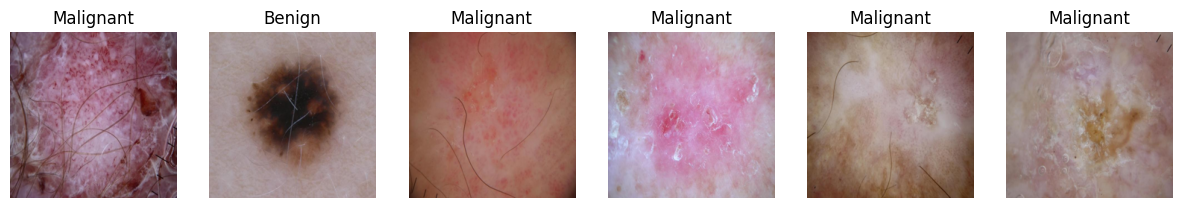

In [14]:
# PURPOSE: display the first 6 training images with their labels.
# HOW: matplotlib wants (H, W, 3), so permute moves the channels back to the end.

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, i in zip(axes, [0, 1, 2, 3, 4, 5]):
    ax.imshow(X_train[i].permute(1, 2, 0)); ax.set_title(CLASSES[y_train[i]]); ax.axis("off")

### 5. The training toolkit — normalize, augment, fit, evaluate

Four small tools that every model below will share.

#### 5.1 `prep`: normalize like ImageNet

ResNet was trained on images scaled with ImageNet's mean and standard deviation, so it must receive the same scale. We use it for all of today's models.

In [15]:
# PURPOSE: turn stored pixels (0-255) into what the network expects.
# HOW: uint8 -> float in [0, 1] -> subtract the mean and divide by the std, per channel.

# view(1, 3, 1, 1): one value per channel, in a shape that applies to a whole batch
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)   # ImageNet statistics
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def prep(xb):
    return (xb.to(device).float() / 255 - MEAN) / STD

# Check by hand: a red value of 200 becomes 1.31
print(((200 / 255) - 0.485) / 0.229)             # 1.31

1.3070468362017296


#### 5.2 `augment`: random flips

A lesion has no "up", so a flipped lesion keeps its diagnosis. The model sees slightly different images in each epoch (Session 3).

In [16]:
# PURPOSE: add variety to the training images without changing their labels.
# HOW: for each image, flip a coin; torch.where takes the flipped version where the coin says yes.

def augment(xb):
    n = xb.size(0)                                           # number of images in the batch

    # --- Coin 1: left-right flip ---
    # torch.rand gives n random numbers between 0 and 1, one per image.
    # "< 0.5" turns each number into True or False, so each image has a 50% chance.
    # Shape (n, 1, 1, 1): one decision per image, applied to all of its channels and pixels.
    # device=xb.device: create the numbers where the images are (CPU or GPU).
    flip_h = torch.rand(n, 1, 1, 1, device=xb.device) < 0.5  # one True/False per image

    # xb.flip(3) reverses dimension 3 (the width), which mirrors the images left-right.
    # torch.where(condition, a, b) chooses image by image:
    # where the condition is True it takes a (flipped), otherwise b (original).
    xb = torch.where(flip_h, xb.flip(3), xb)                 # left-right

    # --- Coin 2: up-down flip, decided independently ---
    flip_v = torch.rand(n, 1, 1, 1, device=xb.device) < 0.5

    # xb.flip(2) reverses dimension 2 (the height), which mirrors the images up-down.
    # So each image ends up in one of 4 versions: original, left-right, up-down, or both.
    # The batch shape does not change, and the labels stay the same.
    return torch.where(flip_v, xb.flip(2), xb)               # up-down

#### 5.3 `predict` and `fit`: Session 6's training loop

The same steps as Session 6: **zero_grad → forward + loss → backward → step**. The model changes, but the loop doesn't. After each epoch we measure validation macro-F1 and remember the best weights.

In [17]:
# PURPOSE: one function to predict and one to train, reused by every model below.
# HOW: batches of images go through Session 6's loop, with class weights in the loss.

from sklearn.metrics import f1_score, accuracy_score, ConfusionMatrixDisplay

# Class weights, as in Session 6: n / (3 * n_c), so mistakes on rare classes cost more
class_weights = (len(y_train) / (3 * torch.bincount(y_train).float())).to(device)

# predict: evaluation mode, no gradients; take the class with the highest score, batch by batch
@torch.no_grad()
def predict(model, X, batch_size=128):
    model.eval()
    return torch.cat([model(prep(X[i:i + batch_size])).argmax(1).cpu() for i in range(0, len(X), batch_size)])

def fit(model, params, epochs, lr, batch_size=64, aug=True):
    model.to(device)
    optimizer = torch.optim.Adam(params, lr=lr)          # params: only the weights we want to train
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    history, best = [], {"f1": -1}
    for epoch in range(epochs):
        model.train()
        t0, total = time.perf_counter(), 0.0
        order = torch.randperm(len(X_train))             # new random order in each epoch
        for i in range(0, len(X_train), batch_size):
            # Take the next batch, normalize it and (optionally) flip it
            idx = order[i:i + batch_size]
            xb, yb = prep(X_train[idx]), y_train[idx].to(device)
            if aug:
                xb = augment(xb)

            # The training step from Session 6
            optimizer.zero_grad()                        # forget the old gradients
            loss = loss_fn(model(xb), yb)                # forward + loss
            loss.backward()                              # backprop: compute the gradients
            optimizer.step()                             # update the weights
            total += loss.item() * len(idx)

        # End of the epoch: score on validation and remember the best weights so far
        f1 = f1_score(y_val, predict(model, X_val), average="macro")
        history.append({"epoch": epoch, "train_loss": total / len(X_train), "val_f1": f1})
        print(f"epoch {epoch}  loss {total / len(X_train):.3f}  val macro-F1 {f1:.3f}  ({time.perf_counter() - t0:.0f} s)")
        if f1 > best["f1"]:
            best = {"f1": f1, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
    model.load_state_dict(best["state"])          # early stopping: keep the best epoch
    return pd.DataFrame(history).set_index("epoch"), best

### 6. Train the CNN from scratch

Random weights, 3,593 lesions, 10 epochs. Is that enough to learn good filters?

#### 6.1 Training

Look at the validation macro-F1 from one epoch to the next, not only at the best value.

In [18]:
# PURPOSE: train SimpleCNN from random weights, as a reference.
# HOW: call fit with all the model's weights and a learning rate of 1e-3.

torch.manual_seed(0)
scratch = SimpleCNN()
hist_scratch, best_scratch = fit(scratch, scratch.parameters(), epochs=10, lr=1e-3)
print("best epoch", best_scratch["epoch"], "val macro-F1", round(best_scratch["f1"], 3))   # best epoch 3, val macro-F1 0.555 (epochs jump between 0.40 and 0.56)

epoch 0  loss 1.566  val macro-F1 0.447  (4 s)
epoch 1  loss 0.964  val macro-F1 0.453  (3 s)
epoch 2  loss 0.946  val macro-F1 0.461  (3 s)
epoch 3  loss 0.912  val macro-F1 0.516  (3 s)
epoch 4  loss 0.908  val macro-F1 0.487  (3 s)
epoch 5  loss 0.872  val macro-F1 0.491  (3 s)
epoch 6  loss 0.838  val macro-F1 0.473  (3 s)
epoch 7  loss 0.904  val macro-F1 0.497  (3 s)
epoch 8  loss 0.820  val macro-F1 0.488  (3 s)
epoch 9  loss 0.784  val macro-F1 0.520  (3 s)
best epoch 9 val macro-F1 0.52


#### 6.2 What did its first layer learn?

These are its 16 filters of 3×3×3, shown as tiny color images. Compare them with ResNet's filters in section 7.

"\nf.permute(1, 2, 0) changes each filter from (3, 3, 3) as (channels, height, width) to (height, width, channels), the order imshow expects.\nimshow then reads the three grids as the R, G and B values of an image: 3×3 pixels, each with 3 values.\nThe weights are first rescaled to [0, 1], because colors can't be negative.\n"

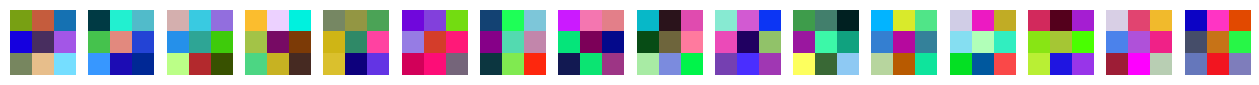

In [19]:
# PURPOSE: look inside the trained network.
# HOW: read the weights of the first conv layer and draw each filter as an image.

w = scratch.features[0].weight.detach().cpu()                       # (16, 3, 3, 3)
fig, axes = plt.subplots(1, 16, figsize=(16, 1.4))
for ax, f in zip(axes, w):
    # Weights can be negative, so rescale each filter to [0, 1] just to display it
    f = f.permute(1, 2, 0); ax.imshow((f - f.min()) / (f.max() - f.min())); ax.axis("off")

"""
f.permute(1, 2, 0) changes each filter from (3, 3, 3) as (channels, height, width) to (height, width, channels), the order imshow expects.
imshow then reads the three grids as the R, G and B values of an image: 3×3 pixels, each with 3 values.
The weights are first rescaled to [0, 1], because colors can't be negative.
"""

### 7. A pretrained ResNet-18

This network learned its 11.7 million weights on 1.28 million ImageNet photos. Before using it, we look inside.

#### 7.1 Loading the network

Its last layer, `fc`, maps 512 numbers to ImageNet's 1,000 classes. The table shows how many weights each part has.

In [20]:
# PURPOSE: load ResNet-18 with its ImageNet weights and see how it is built.
# HOW: torchvision downloads the weights; named_children lists the main blocks.

from torchvision.models import resnet18, ResNet18_Weights

resnet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)       # downloads ~45 MB the first time
print(resnet.fc)                                                # Linear(in_features=512, out_features=1000)
print(f"{count(resnet):,} parameters")                          # 11,689,512
for name, child in resnet.named_children():
    print(f"{name:8s} {count(child):>10,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 177MB/s]


Linear(in_features=512, out_features=1000, bias=True)
11,689,512 parameters
conv1         9,408
bn1             128
relu              0
maxpool           0
layer1      147,968
layer2      525,568
layer3    2,099,712
layer4    8,393,728
avgpool           0
fc          513,000


#### 7.2 Its first layer: 64 filters learned on ImageNet

Nobody designed these. Look for edges at different angles and for color blobs, and compare them with our from-scratch filters.

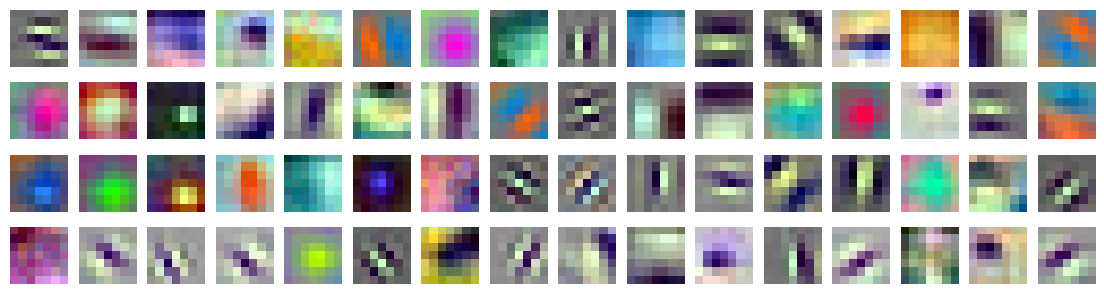

In [21]:
# PURPOSE: see what a well-trained first layer looks like.
# HOW: same as cell 6.2, now with 64 filters of 7x7x3.

w = resnet.conv1.weight.detach()                                 # (64, 3, 7, 7)
fig, axes = plt.subplots(4, 16, figsize=(14, 3.6))
for ax, f in zip(axes.ravel(), w):
    f = f.permute(1, 2, 0); ax.imshow((f - f.min()) / (f.max() - f.min())); ax.axis("off")

#### 7.3 One lesion through the network

We show one feature map after each of the four stages. As we go deeper, the maps get smaller and coarser, and there are more of them.

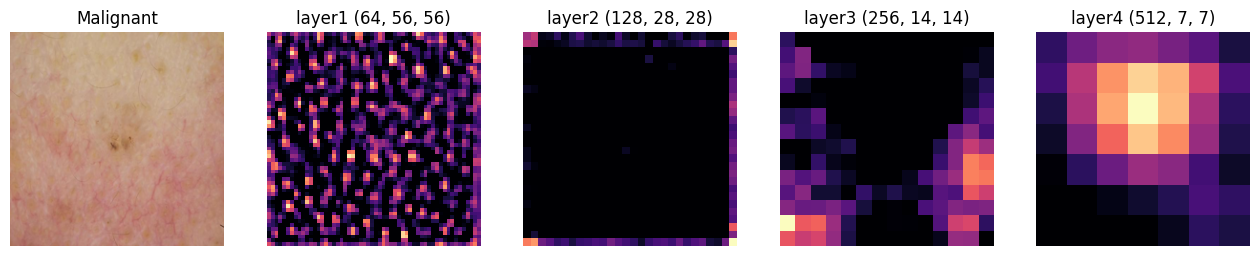

In [22]:
# PURPOSE: see the feature hierarchy on a real lesion.
# HOW: run the network stage by stage and draw the most varied map of each stage.

x = prep(X_val[:1])                                              # the first validation image
resnet.to(device).eval()
with torch.no_grad():
    # The layers that come before layer1
    h = resnet.maxpool(resnet.relu(resnet.bn1(resnet.conv1(x))))
    fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
    axes[0].imshow(X_val[0].permute(1, 2, 0)); axes[0].set_title(CLASSES[y_val[0]]); axes[0].axis("off")
    for ax, name in zip(axes[1:], ["layer1", "layer2", "layer3", "layer4"]):
        h = getattr(resnet, name)(h)                             # run the next stage
        k = h[0].flatten(1).std(1).argmax()                      # the map with the largest variation
        ax.imshow(h[0, k].cpu(), cmap="magma"); ax.set_title(f"{name} {tuple(h.shape[1:])}"); ax.axis("off")

### 8. Feature extraction — 512 learned numbers instead of our 33

**Strategy 1: freeze the backbone.** ResNet-18 becomes a feature extractor, and only a new last layer is trained.

#### 8.1 Turning each lesion into 512 numbers

We replace the last layer with `nn.Identity()`, which does nothing, so the network outputs its 512 internal numbers. It's Session 5's idea of a feature vector, but these numbers were learned, not designed. Since the backbone never changes, we compute them only once.

In [23]:
# PURPOSE: compute a 512-number description of every lesion.
# HOW: remove the head, then run all the images through the network without gradients.

resnet.fc = nn.Identity()
resnet.eval()

@torch.no_grad()
def embed(X, batch_size=128):
    return torch.cat([resnet(prep(X[i:i + batch_size])).cpu() for i in range(0, len(X), batch_size)])

t0 = time.perf_counter()
F_train, F_val, F_test = embed(X_train), embed(X_val), embed(X_test)
print(F_train.shape, f"{time.perf_counter() - t0:.0f} s")       # torch.Size([3593, 512])

torch.Size([3667, 512]) 5 s


#### 8.2 Training only a new last layer

From here it's a tabular problem, like Session 6: 512 numbers per lesion and 3 classes. The new layer has only 1,539 weights. The number to beat is the forest's 0.534.

In [24]:
# PURPOSE: train the new head on the 512 numbers and score it on validation.
# HOW: one nn.Linear(512, 3), and Session 6's loop over batches of features.

from torch.utils.data import TensorDataset

torch.manual_seed(0)
head = nn.Linear(512, 3).to(device)                       # 512 x 3 weights + 3 biases = 1,539
optimizer = torch.optim.Adam(head.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss(weight=class_weights)
loader = DataLoader(TensorDataset(F_train, y_train), batch_size=64, shuffle=True)
for epoch in range(25):
    for fb, yb in loader:
        optimizer.zero_grad()
        loss = loss_fn(head(fb.to(device)), yb.to(device))
        loss.backward()
        optimizer.step()

# Score on validation
with torch.no_grad():
    head_val_f1 = f1_score(y_val, head(F_val.to(device)).argmax(1).cpu(), average="macro")
print(f"frozen ResNet-18 + linear head: val macro-F1 = {head_val_f1:.3f}")      # 0.632

frozen ResNet-18 + linear head: val macro-F1 = 0.563


#### 8.3 Where are the errors?

Rows are the truth and columns are the prediction. Look at the small Indeterminate row: Session 5's forest found only 2 of those 17 lesions.

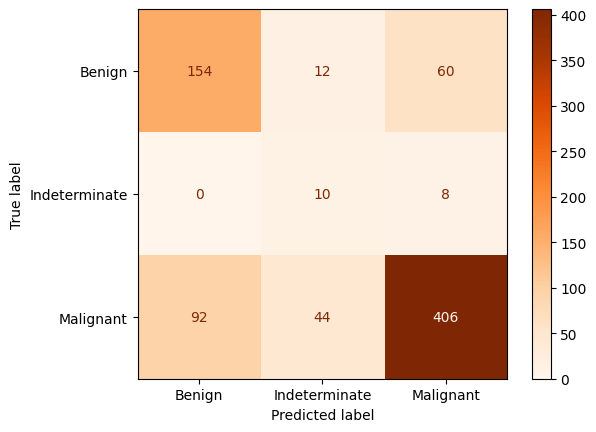

In [25]:
# PURPOSE: see the errors per class, which a single score hides.
# HOW: predict on validation and draw the confusion matrix.

with torch.no_grad():
    head_val_pred = head(F_val.to(device)).argmax(1).cpu()
ConfusionMatrixDisplay.from_predictions(y_val, head_val_pred, display_labels=CLASSES, cmap="Oranges");
# Indeterminate row: 10 of 17 found (Session 5's forest: 2)

### 9. Partial fine-tuning — unfreeze `layer4`

**Strategy 2: let the last block adapt to skin lesions.** The earlier blocks stay frozen.

#### 9.1 Choosing what to train

We take a fresh pretrained ResNet with a new head. `requires_grad = False` freezes a weight: PyTorch computes no gradient for it, so it never changes.

In [26]:
# PURPOSE: freeze everything except layer4 and the new head.
# HOW: loop over all the weights and switch requires_grad according to the layer's name.

torch.manual_seed(0)
model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(512, 3)                                     # new head: 3 classes
for name, p in model.named_parameters():
    p.requires_grad = name.startswith("layer4") or name.startswith("fc")

# Keep the list of weights that will be trained, and count them
trainable = [p for p in model.parameters() if p.requires_grad]
print(f"training {sum(p.numel() for p in trainable):,} of {count(model):,} parameters")

training 8,395,267 of 11,178,051 parameters


#### 9.2 Fine-tuning

We use a smaller learning rate (1e-4): the pretrained weights are already good, so we only nudge them. Flips are on. Now the images must go through the network in every epoch, so this is the slowest step so far.

In [27]:
# PURPOSE: let layer4 adapt to dermoscopy.
# HOW: the same fit function as in section 6, given only the trainable weights.

hist_ft, best_ft = fit(model, trainable, epochs=6, lr=1e-4)
print("best epoch", best_ft["epoch"], "val macro-F1", round(best_ft["f1"], 3))     # best epoch 1, val macro-F1 0.614 (epochs: 0.54, 0.61, 0.59, 0.59, 0.60, 0.59)

epoch 0  loss 0.849  val macro-F1 0.524  (6 s)
epoch 1  loss 0.600  val macro-F1 0.591  (6 s)
epoch 2  loss 0.461  val macro-F1 0.574  (6 s)
epoch 3  loss 0.414  val macro-F1 0.571  (6 s)
epoch 4  loss 0.347  val macro-F1 0.638  (6 s)
epoch 5  loss 0.291  val macro-F1 0.562  (6 s)
best epoch 4 val macro-F1 0.638


#### 9.3 Where are the errors now?

Compare with the matrix of the frozen model in 8.3. With only 599 validation lesions, small differences can be noise.

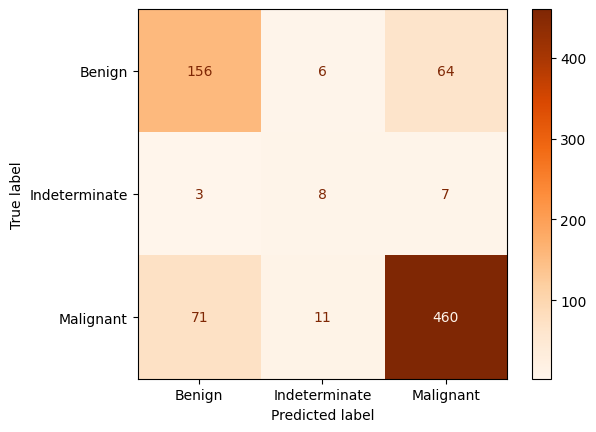

In [28]:
# PURPOSE: compare the errors of the fine-tuned model with the frozen one.
# HOW: same as cell 8.3; predict() already restored the model's best epoch.

ConfusionMatrixDisplay.from_predictions(y_val, predict(model, X_val), display_labels=CLASSES, cmap="Oranges");

### 11. Mini challenge — unfreeze more

Start from a fresh pretrained ResNet-18 and also unfreeze `layer3` (train `layer3` + `layer4` + `fc`) with `lr=1e-4`.

Note the number of trainable parameters, the seconds per epoch and the best **validation** macro-F1. Compare with `layer4` only: was it worth it? The test set stays closed.

In [29]:
# PURPOSE: train layer3 as well as layer4, and see whether the extra cost is worth it.
# HOW: same as 9.1, with layer3 added to the names that stay trainable.

torch.manual_seed(0)
model3 = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model3.fc = nn.Linear(512, 3)
for name, p in model3.named_parameters():
    p.requires_grad = name.startswith(("layer3", "layer4", "fc"))

trainable3 = [p for p in model3.parameters() if p.requires_grad]
print(f"training {sum(p.numel() for p in trainable3):,} of {count(model3):,} parameters")

t0 = time.perf_counter()
hist3, best3 = fit(model3, trainable3, epochs=6, lr=1e-4)
print(f"best epoch {best3['epoch']}  val macro-F1 {best3['f1']:.3f}  "
      f"{(time.perf_counter() - t0) / 6:.0f} s per epoch")

training 10,494,979 of 11,178,051 parameters
epoch 0  loss 0.834  val macro-F1 0.524  (7 s)
epoch 1  loss 0.573  val macro-F1 0.538  (7 s)
epoch 2  loss 0.444  val macro-F1 0.568  (7 s)
epoch 3  loss 0.384  val macro-F1 0.637  (8 s)
epoch 4  loss 0.314  val macro-F1 0.642  (8 s)
epoch 5  loss 0.255  val macro-F1 0.608  (8 s)
best epoch 4  val macro-F1 0.642  7 s per epoch


In [30]:
pd.DataFrame([
    {"unfrozen": "layer4 + fc",
     "trainable parameters": sum(p.numel() for p in trainable),
     "best val macro-F1": round(best_ft["f1"], 3)},
    {"unfrozen": "layer3 + layer4 + fc",
     "trainable parameters": sum(p.numel() for p in trainable3),
     "best val macro-F1": round(best3["f1"], 3)},
])

,unfrozen,trainable parameters,best val macro-F1
0,layer4 + fc,8395267,0.638
1,layer3 + layer4 + fc,10494979,0.642


##Class 7 Homework

In [31]:
# PURPOSE: pick the best Session 7 model on VALIDATION, then score it ONCE on TEST.
# HOW: all four candidates in one dict; the frozen head scores from F_test, the
# fine-tuned models from X_test through predict().

s7 = {
    "CNN from scratch":              best_scratch["f1"],
    "ResNet-18 frozen + head":       head_val_f1,
    "ResNet-18 layer4 fine-tuned":   best_ft["f1"],
    "ResNet-18 layer3+4 fine-tuned": best3["f1"],
}
best_name = max(s7, key=s7.get)
print("best on validation:", best_name, round(s7[best_name], 3))

if best_name == "ResNet-18 frozen + head":
    with torch.no_grad():
        test_pred = head(F_test.to(device)).argmax(1).cpu()
else:
    best_model = {"CNN from scratch": scratch,
                  "ResNet-18 layer4 fine-tuned": model,
                  "ResNet-18 layer3+4 fine-tuned": model3}[best_name]
    test_pred = predict(best_model, X_test)

s7_test = f1_score(y_test, test_pred, average="macro")
print(f"TEST macro-F1 = {s7_test:.3f}")

best on validation: ResNet-18 layer3+4 fine-tuned 0.642
TEST macro-F1 = 0.590


In [32]:
# PURPOSE: the scoreboard across Sessions 5, 6 and 7.
# Session 5 numbers: m2_baseline/Session5/results.txt.  Session 6: my Session 6 notebook.

MLP_VAL, MLP_TEST = None, None        # <- my Session 6 MLP numbers go here

scoreboard = pd.DataFrame([
    {"session": 5, "model": "majority (always Malignant)", "val": 0.272, "test": 0.278},
    {"session": 5, "model": "random forest, 24 histogram features", "val": 0.511, "test": 0.525},
    {"session": 6, "model": "MLP 33-64-3 on handcrafted features", "val": MLP_VAL, "test": MLP_TEST},
    {"session": 7, "model": "CNN from scratch", "val": round(best_scratch["f1"], 3), "test": None},
    {"session": 7, "model": "ResNet-18 frozen + linear head", "val": round(head_val_f1, 3), "test": None},
    {"session": 7, "model": "ResNet-18, layer4 fine-tuned", "val": round(best_ft["f1"], 3), "test": None},
    {"session": 7, "model": "ResNet-18, layer3+4 fine-tuned", "val": round(best3["f1"], 3), "test": None},
])
scoreboard.loc[scoreboard["model"].str.contains(best_name.split(" fine")[0].split(" +")[0]) &
               (scoreboard["session"] == 7), "test"] = round(s7_test, 3)
scoreboard

,session,model,val,test
0,5,majority (always Malignant),0.272,0.278
1,5,"random forest, 24 histogram features",0.511,0.525
2,6,MLP 33-64-3 on handcrafted features,NaN,NaN
3,7,CNN from scratch,0.520,NaN
4,7,ResNet-18 frozen + linear head,0.563,NaN
5,7,"ResNet-18, layer4 fine-tuned",0.638,NaN
6,7,"ResNet-18, layer3+4 fine-tuned",0.642,NaN


In [33]:
# PURPOSE: strategy 3 - every weight is trainable, not just layer3/layer4.
# HOW: a fresh pretrained ResNet-18, nothing frozen, and a SMALLER learning rate:
# every pretrained weight moves now, so 1e-4 would wreck what ImageNet learned.

torch.manual_seed(0)
model_all = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model_all.fc = nn.Linear(512, 3)
for p in model_all.parameters():
    p.requires_grad = True

print(f"training {count(model_all):,} parameters (all of them)")

t0 = time.perf_counter()
hist_all, best_all = fit(model_all, model_all.parameters(), epochs=6, lr=1e-5)
print(f"best epoch {best_all['epoch']}  val macro-F1 {best_all['f1']:.3f}  "
      f"{(time.perf_counter() - t0) / 6:.0f} s per epoch")

training 11,178,051 parameters (all of them)
epoch 0  loss 1.061  val macro-F1 0.522  (13 s)
epoch 1  loss 0.819  val macro-F1 0.517  (13 s)
epoch 2  loss 0.715  val macro-F1 0.509  (13 s)
epoch 3  loss 0.664  val macro-F1 0.500  (13 s)
epoch 4  loss 0.613  val macro-F1 0.528  (13 s)
epoch 5  loss 0.573  val macro-F1 0.529  (13 s)
best epoch 5  val macro-F1 0.529  13 s per epoch
